<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/trashnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset TrashNet via kagglehub ---
Using Colab cache for faster access to the 'trashnet' dataset.
Path to dataset files: /kaggle/input/trashnet
Total gambar valid: 2527
Daftar Kategori Terdeteksi: ['metal', 'glass', 'paper', 'trash', 'cardboard', 'plastic']
Sampel citra untuk Modul 1-3: /kaggle/input/trashnet/dataset-resized/metal/metal375.jpg



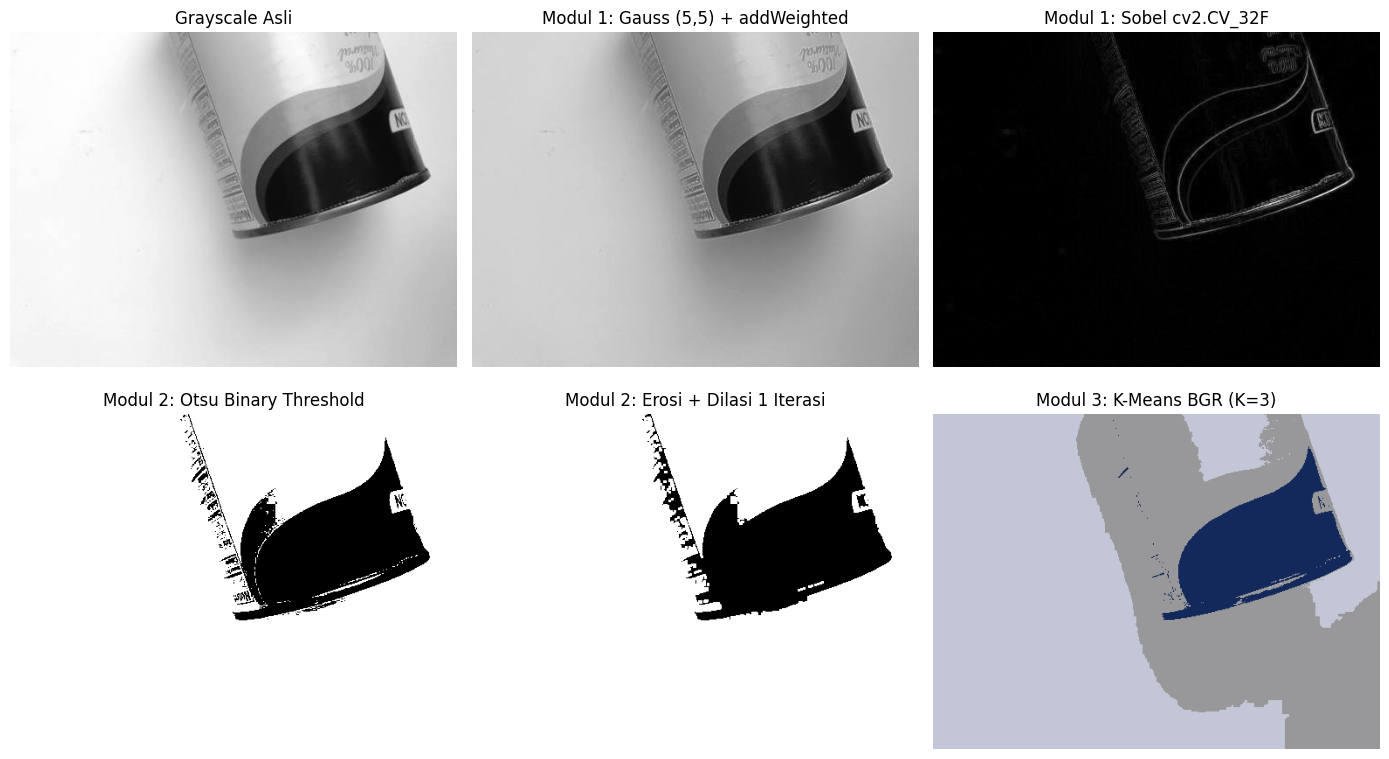


--- Modul 4: Membagi Dataset & Preprocessing Transfer Learning ---
Found 2021 validated image filenames belonging to 6 classes.
Found 506 validated image filenames belonging to 6 classes.

--- Melatih Model EfficientNetB0 (Fine-Tuning) ---
Epoch 1/2
64/64 ━━━━━━━━━━━━━━━━━━━━ 113s 2s/step - accuracy: 0.2128 - loss: 1.7811 - val_accuracy: 0.1601 - val_loss: 1.8446
Epoch 2/2
64/64 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.2207 - loss: 1.7587 - val_accuracy: 0.2352 - val_loss: 1.8038
16/16 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step

================ CLASSIFICATION REPORT ================
              precision    recall  f1-score   support

   cardboard       0.00      0.00      0.00        81
       glass       0.00      0.00      0.00       100
       metal       0.00      0.00      0.00        82
       paper       0.24      1.00      0.38       119
     plastic       0.00      0.00      0.00        97
       trash       0.00      0.00      0.00        27

    accuracy                    

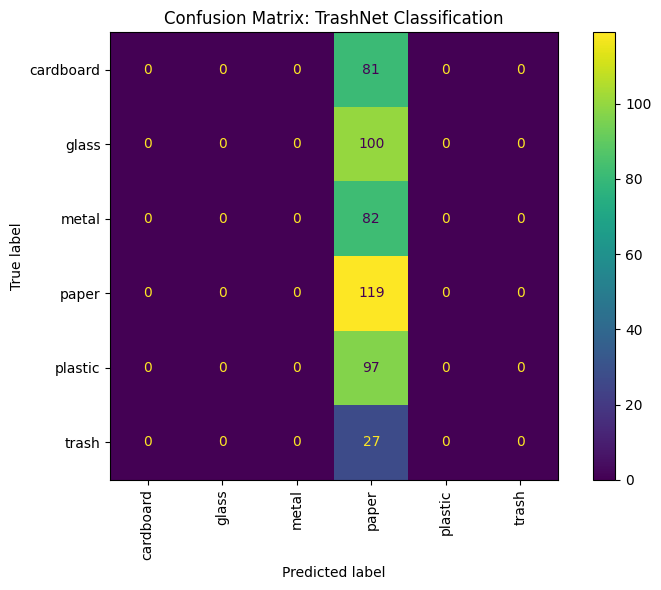

In [5]:
import os
# Matikan log verbose TensorFlow agar tidak membebani output
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import kagglehub

# Membatasi alokasi memori GPU agar tidak terjadi Out of Memory (OOM)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

# =====================================================================
# 0. UNDUH DATASET TRASHNET MENGGUNAKAN KAGGLEHUB
# =====================================================================
print("--- Mengunduh Dataset TrashNet via kagglehub ---")
path = kagglehub.dataset_download("feyzazkefe/trashnet")
print("Path to dataset files:", path)

# 1. Cari semua file gambar (.jpg / .jpeg / .png) di seluruh subfolder dataset
image_files = glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpeg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.png"), recursive=True)

if not image_files:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam dataset TrashNet!")

# 2. Susun DataFrame berdasarkan nama direktori kelas
data = []
for img_path in image_files:
    class_name = os.path.basename(os.path.dirname(img_path))
    data.append({'file_path': img_path, 'class_str': class_name})

df = pd.DataFrame(data)

# Filter folder non-kelas jika ada (ambil kelas yang memiliki sampel gambar mencukupi)
class_counts = df['class_str'].value_counts()
valid_classes = class_counts[class_counts > 5].index
df = df[df['class_str'].isin(valid_classes)].reset_index(drop=True)

print(f"Total gambar valid: {len(df)}")
print(f"Daftar Kategori Terdeteksi: {df['class_str'].unique().tolist()}")

# Ambil 1 sampel citra untuk demonstrasi Modul 1-3
sample_img_path = df['file_path'].iloc[0]
print(f"Sampel citra untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Gauss (5,5), addWeighted Sharpening & Sobel (cv2.CV_32F)
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Reduksi pembiasan spektrum partikel keruh menggunakan filter Gauss (5,5)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Penajaman ulang sisa struktur material plastik berdasarkan fungsi addWeighted
    high_freq_detail = cv2.subtract(gray, blurred)
    sharpened = cv2.addWeighted(gray, 1.0, high_freq_detail, 1.5, 0)

    # 3. Lacak batas lipatan sudut kemasan dengan magnitudo Sobel vertikal & horizontal (cv2.CV_32F)
    sobel_x = cv2.Sobel(sharpened, cv2.CV_32F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_32F, 0, 1, ksize=3)

    sobel_mag = cv2.magnitude(sobel_x, sobel_y)
    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Binerisasi Otsu & Morfologi Erosi-Dilasi (Opening 1 Iterasi)
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Pemisahan batas intensitas objek siluet berbasis Otsu
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Ratakan tepi biner via getStructuringElement: erosi disusul dilasi 1 perulangan (Opening)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    eroded = cv2.erode(otsu_thresh, kernel, iterations=1)
    clean_mask = cv2.dilate(eroded, kernel, iterations=1)

    return otsu_thresh, clean_mask


# =====================================================================
# MODUL 3: Klasterisasi K-Means BGR (3 Sentroid Warna)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)

    # 1. Alihkan perlakuan citra berwarna BGR ke dalam rentetan list observasi panjang
    pixel_values = img_bgr.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. Bagi warna terdistorsi menjadi 3 klaster sentroid iteratif:
    # - Palet latar belakang perairan
    # - Bayangan pasir dan karang alami
    # - Corak blok warna sintetis cerah plastik
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_bgr.shape)

    # Konversi BGR ke RGB untuk visualisasi Matplotlib
    segmented_rgb = cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB)

    return segmented_rgb


# =====================================================================
# MODUL 4: Transfer Learning EfficientNetB0 (RandomRotation & Unfreeze 20 Layer)
# =====================================================================
def modul_4_train_and_eval(df, img_size=(128, 128), batch_size=32, epochs=2):
    print("\n--- Modul 4: Membagi Dataset & Preprocessing Transfer Learning ---")

    # Split Stratified (80% Train, 20% Val)
    train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['class_str'])

    datagen = ImageDataGenerator(rescale=1./255)

    train_gen = datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_gen = datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    num_classes = len(train_df['class_str'].unique())

    # 1. Muat Bobot Transfer Learning ImageNet
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_size[0], img_size[1], 3))
    base_model.trainable = True

    # 2. Lepaskan nilai trainable pada 20 lapisan fitur ujung spesifik EfficientNetB0
    for layer in base_model.layers[:-20]:
        layer.trainable = False

    # 3. Konstruksi Jaringan dengan Lapisan RandomRotation
    inputs = layers.Input(shape=(img_size[0], img_size[1], 3))

    # Blok rotasi kompensasi kamera bawah laut
    x = layers.RandomRotation(0.2)(inputs)
    x = base_model(x, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model EfficientNetB0 (Fine-Tuning) ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # 4. Evaluasi Prediksi pada Data Validasi
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    labels_map = {v: k for k, v in val_gen.class_indices.items()}
    class_names = [labels_map[i] for i in range(num_classes)]

    print("\n================ CLASSIFICATION REPORT ================")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # 5. Sajikan validasi fungsi grafis ConfusionMatrixDisplay Matplotlib berwarna
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(8, 6))
    disp.plot(cmap='viridis', ax=ax, xticks_rotation='vertical')
    plt.title('Confusion Matrix: TrashNet Classification')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI PIPELINE
# =====================================================================
if __name__ == "__main__":
    # Run Modul 1, 2, dan 3
    gray_img, sharpened_img, sobel_uint8 = modul_1_processing(sample_img_path)
    otsu_thresh, clean_mask = modul_2_processing(sharpened_img)
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Hasil Modul 1 - 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: Gauss (5,5) + addWeighted')

    axes[0, 2].imshow(sobel_uint8, cmap='gray')
    axes[0, 2].set_title('Modul 1: Sobel cv2.CV_32F')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Binary Threshold')

    axes[1, 1].imshow(clean_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Erosi + Dilasi 1 Iterasi')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means BGR (K=3)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Run Modul 4 (Fine Tuning & Confusion Matrix Matplotlib) dengan Epochs=2
    modul_4_train_and_eval(df, epochs=2)